# 1. Research objective

Experiment 1 predicts observed unplanned hospital readmission within 30 days of discharge using the approved 24-hour admission features. Logistic Regression and XGBoost provide a model and validated attributions for studying the faithfulness of local Qwen3 explanations. This is a retrospective research experiment. Predictive associations and SHAP contributions do not establish clinical effects.

## 2. Environment and configuration

Select the HRP Python 3.12 kernel in VS Code. Review mode reads the saved private bundle and displays aggregate outputs. Train mode runs the full pipeline. Regenerate mode uses saved models, with independent switches for global SHAP and the 72-case dataset. It creates a new bundle with the original fitted model ID.

In [1]:
import os
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

SOURCE = next(
    (p for p in (Path.cwd(), Path.cwd() / "src", Path.cwd() / "HRP/src")
     if (p / "run_models.py").is_file()),
    None,
)
if SOURCE is None:
    raise RuntimeError("Open the notebook from AI380H, HRP, or HRP/src.")
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from modeling import DEFAULT_COHORT_ROOT, Settings, choose_cohort, read_json
from run_models import Experiment, latest_model_run, regenerate, verify_run

MODE = "review"            # "review", "train", or "regenerate"
COHORT_RUN = None          # Explicit path, or latest validated run under COHORT_ROOT
MODEL_RUN = None           # Explicit private bundle, or latest under OUTPUT_ROOT
RECOMPUTE_SHAP = False     # Regenerate mode: held-out global sample and diagnostics
REGENERATE_CASES = False   # Regenerate mode: 72 cases and their local explanations
COHORT_ROOT = Path(os.environ.get("MIMIC_OUTPUT_DIR", DEFAULT_COHORT_ROOT)).expanduser()
OUTPUT_ROOT = Path(os.environ.get("HRP_MODEL_OUTPUT_DIR", COHORT_ROOT / "model-runs")).expanduser()
SETTINGS = Settings()

if MODE not in {"review", "train", "regenerate"}:
    raise ValueError("Choose review, train, or regenerate.")
selected_bundle = MODEL_RUN or latest_model_run(OUTPUT_ROOT)
bundle = Path(selected_bundle).expanduser().resolve() if selected_bundle else None

## 3. Load and validate cohort

Verify the stored checksums, admission coverage and cohort and partition counts against the readiness manifest. All admissions for a patient stay in the original 70/15/15 patient split. Review mode uses the verified source metadata in the saved bundle.

In [2]:
experiment = manifest = source = None
if MODE in {"train", "regenerate"}:
    cohort = choose_cohort(COHORT_ROOT, COHORT_RUN or os.environ.get("HRP_COHORT_RUN"))
if MODE == "train":
    experiment = Experiment(cohort, SETTINGS)
    source = experiment.source
elif bundle is not None:
    manifest = verify_run(bundle)
    source = manifest["source"]

if source:
    print(source["id"])
    display(pd.DataFrame([source["cohort"]]), pd.DataFrame(source["partitions"]))
else:
    print("No saved result. Set MODEL_RUN to a bundle path or set MODE to train.")

run-20261122T212339Z-c71630d2


,patients,admissions,readmissions,readmission_pct
0,175246,358194,40205,11.224364


,partition,patients,admissions,readmissions,readmission_pct
0,train,122672,251031,28060,11.177902
1,validation,26287,53784,6156,11.445783
2,test,26287,53379,5989,11.219768


## 4. Feature schema and preprocessing

The saved schema supplies the ordered allowlist. Numeric features use training medians, and Logistic Regression also standardizes them. XGBoost uses median-filled numeric values with their original scale. Both models retain existing lab missingness indicators, impute missing categorical values with a fixed token and one-hot encode categories. Unseen categories map to an all-zero block for that feature. The fitted encoder map identifies which dummy columns belong to each original predictor.

In [3]:
if experiment:
    display(experiment.feature_audits["train"])
elif manifest:
    display(pd.read_csv(bundle / "feature_audit.csv"))

,feature,dtype,missing,missing_pct,min,max,categories,partition
0,age,Int64,0,0.000000,18.0,106.0,NaN,train
1,gender,object,0,0.000000,NaN,NaN,2.0,train
2,admission_type,object,0,0.000000,NaN,NaN,9.0,train
3,admission_location,object,0,0.000000,NaN,NaN,11.0,train
4,insurance,object,2820,1.123367,NaN,NaN,5.0,train
...,...,...,...,...,...,...,...,...
70,bun_missing,int8,0,0.000000,0.0,1.0,NaN,test
71,glucose,float64,15482,29.003915,25.0,1530.0,NaN,test
72,glucose_missing,int8,0,0.000000,0.0,1.0,NaN,test
73,bicarbonate,float64,15179,28.436276,3.0,49.0,NaN,test


## 5. Logistic Regression training

Fit two L2-regularized candidates with the LBFGS solver and uniform class weights. Select by validation average precision, using lower Brier score and candidate order as tie-breakers. A convergence warning disqualifies a candidate.

In [4]:
if experiment:
    display(experiment.fit("logistic"))
elif manifest:
    display(pd.DataFrame(manifest["candidates"]["logistic"]))

,candidate,config,training_seconds,converged,roc_auc,average_precision,brier,mean_probability,prevalence,iterations,selected
0,0,"{'C': 0.1, 'solver': 'lbfgs', 'max_iter': 1000...",0.660851,True,0.725113,0.264756,0.093635,0.112848,0.114458,47,False
1,1,"{'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000...",0.558905,True,0.725161,0.264861,0.093628,0.112823,0.114458,47,True


## 6. XGBoost training

Fit two fixed CPU histogram configurations with uniform class weights and four threads. The candidates specify different depths, learning rates and tree counts. Apply the same validation selection rule as for Logistic Regression.

In [5]:
if experiment:
    display(experiment.fit("xgboost"))
elif manifest:
    display(pd.DataFrame(manifest["candidates"]["xgboost"]))

,candidate,config,training_seconds,converged,roc_auc,average_precision,brier,mean_probability,prevalence,selected
0,0,"{'max_depth': 3, 'n_estimators': 240, 'learnin...",1.097286,True,0.750269,0.314357,0.090469,0.112842,0.114458,False
1,1,"{'max_depth': 5, 'n_estimators': 320, 'learnin...",1.570504,True,0.755872,0.320972,0.089957,0.112987,0.114458,True


## 7. Validation comparison and model selection

Choose XGBoost when it gains at least 0.005 validation AP, wins on AP in a majority of the patient-grouped validation folds, and its selected probability has a Brier penalty of at most 0.001. Otherwise favor the simpler Logistic Regression baseline. The AP checks use raw scores. The Brier check uses the validation probability source selected in Section 8. These criteria are fixed before test evaluation.

In [6]:
if experiment:
    primary = experiment.validation_decisions()
elif manifest:
    primary = manifest["primary"]
else:
    primary = None
if primary:
    display(pd.DataFrame([primary]))

,model,rationale,xgb_validation_ap_gain,xgb_selected_brier_penalty,xgb_validation_fold_ap_wins,validation_folds
0,xgboost,"XGBoost met the validation AP, probability qua...",0.056111,-0.00367,3,3


## 8. Probability calibration

Compare raw forecasts with out-of-fold Platt calibration of raw margins in three patient-disjoint validation folds. Use sigmoid calibration only if it reduces Brier score by at least 0.0001 and the fold and final sigmoid slopes are positive. If selected, refit the sigmoid on all validation admissions. Select the F1-maximizing threshold from the chosen validation forecasts, using the higher threshold in a tie. SHAP always uses the uncalibrated margin in raw log-odds.

In [7]:
validation = experiment.reports if experiment else (manifest["validation"] if manifest else {})
if validation:
    display(pd.DataFrame.from_dict({
        model: {
            "probability_source": report["probability_source"],
            "raw_brier": report["raw"]["brier"],
            "sigmoid_oof_brier": report["sigmoid_oof"]["brier"],
            "validation_threshold": report["threshold"],
        }
        for model, report in validation.items()
    }, orient="index"))

,probability_source,raw_brier,sigmoid_oof_brier,validation_threshold
logistic,raw,0.093628,0.093627,0.164097
xgboost,raw,0.089957,0.089940,0.196011


## 9. Final test evaluation

Apply the frozen models, calibration decisions and thresholds to the same test admissions. The precision–recall baseline is test prevalence. Report percentile 95% intervals for ROC-AUC and AP after 300 patient-cluster resamples, holding model and threshold fixed. Prediction time includes preprocessing, scoring and any probability calibration.

In [8]:
if experiment:
    display(experiment.evaluate_test())
elif manifest:
    display(pd.read_csv(bundle / "test_comparison.csv"))

,model,roc_auc,average_precision,brier,mean_probability,prevalence,threshold,probability_source,prediction_seconds,precision,recall,f1,training_seconds,roc_auc_ci_low,roc_auc_ci_high,average_precision_ci_low,average_precision_ci_high
0,logistic,0.722138,0.254039,0.092476,0.111406,0.112198,0.164097,raw,0.031291,0.255082,0.454667,0.326812,0.558905,0.712672,0.730423,0.238653,0.272657
1,xgboost,0.755406,0.303790,0.089235,0.111844,0.112198,0.196011,raw,0.050190,0.305091,0.411254,0.350306,1.570504,0.746888,0.763755,0.282361,0.327960


## 10. SHAP global analysis

Explain a fixed held-out sample of up to 1,000 admissions using an independent training reference sample of up to 64 admissions. Use interventional TreeExplainer for XGBoost or LinearExplainer for Logistic Regression. Sum the signed one-hot contributions within each original categorical feature before computing global importance. Lab missingness indicators remain separate. Correlated feature values and missingness can affect attribution interpretation.

In [9]:
global_checks = None
if experiment:
    experiment.prepare_shap()
    global_checks = experiment.explain_global()
elif manifest:
    global_checks = read_json(bundle / "shap_diagnostic_summary.json")

## 11. SHAP local attribution validation

For each explained admission, add the training-reference expected value to the sum of grouped SHAP contributions and compare the result with the raw model margin. Check that the raw probability equals the logistic transform of that margin. Store row-level expected values, sums and reconstruction errors privately. If the model uses a fitted sigmoid, report its probability separately.

In [10]:
if global_checks:
    display(pd.DataFrame([global_checks]))

,rows,max_abs_error,mean_expected_value
0,1000,0.000004,-2.395829


## 12. Selection of 72 explanation cases

Rank held-out admissions by the final predicted probability, breaking exact ties by admission ID, and divide ranks into tertiles. Draw a seeded candidate pool per tertile and select 24 admissions from distinct patients in each. Rotate across observed combinations of lab availability, contribution direction and leading feature. Record achieved diversity and sampling limitations in the bundle. Risk strata are used for sample selection after all fitting decisions are fixed.

In [11]:
case_summary = None
if experiment:
    case_summary = experiment.select_cases(model_id=None)
elif manifest:
    case_summary = read_json(bundle / "case_summary.json")
if case_summary:
    display(pd.Series(case_summary["selected"], name="cases"))
    print(f"Unique patients: {case_summary['unique_patients']}")
    print(f"Maximum selected-case reconstruction error: {case_summary['max_abs_shap_error']:.3g}")

high      24
low       24
medium    24
Name: cases, dtype: int64

Unique patients: 72
Maximum selected-case reconstruction error: 3.12e-06


## 13. Model artifact saving

Train mode writes a new owner-only bundle outside Git. Regenerate mode verifies the original cohort, model files, environment and training reference before writing a new bundle. Both preserve models, validation forecasts, metadata, plots, diagnostics and the case handoff. Keep the full bundle local.

In [12]:
if experiment:
    bundle = experiment.save(OUTPUT_ROOT)
elif MODE == "regenerate":
    if bundle is None:
        raise FileNotFoundError("Regeneration requires an existing model bundle.")
    bundle = regenerate(bundle, cohort, OUTPUT_ROOT, recompute_shap=RECOMPUTE_SHAP,
                        regenerate_cases=REGENERATE_CASES)
if bundle:
    manifest = verify_run(bundle)
    print(bundle)

/Users/sghosh/Library/Application Support/AI380H/MIMIC-IV/model-runs/models-20261122T230904Z-511d7f06


## 14. Summary, limitations and Experiment 2 handoff

Review held-out discrimination and calibration alongside the validation rationale. MIMIC-IV records one healthcare system and has finite follow-up. Administrative features lack historical snapshots, and the cohort uses event storage time as a proxy for lab availability. The case sample is stratified and purposefully diverse, so its prevalence and feature mix describe the sample.

Experiment 2 should verify the saved bundle and join the two case tables on the private admission identifier. Use the original feature values and feature metadata, signed contributions and ranks, and the recorded prediction and SHAP scales. Keep patient rows, local plots and calibration artifacts private. Review aggregate plots before sharing and clear notebook outputs before committing.

XGBoost met the validation AP, probability quality, and fold consistency criteria. CPU histogram training and TreeExplainer support the explanation workflow.


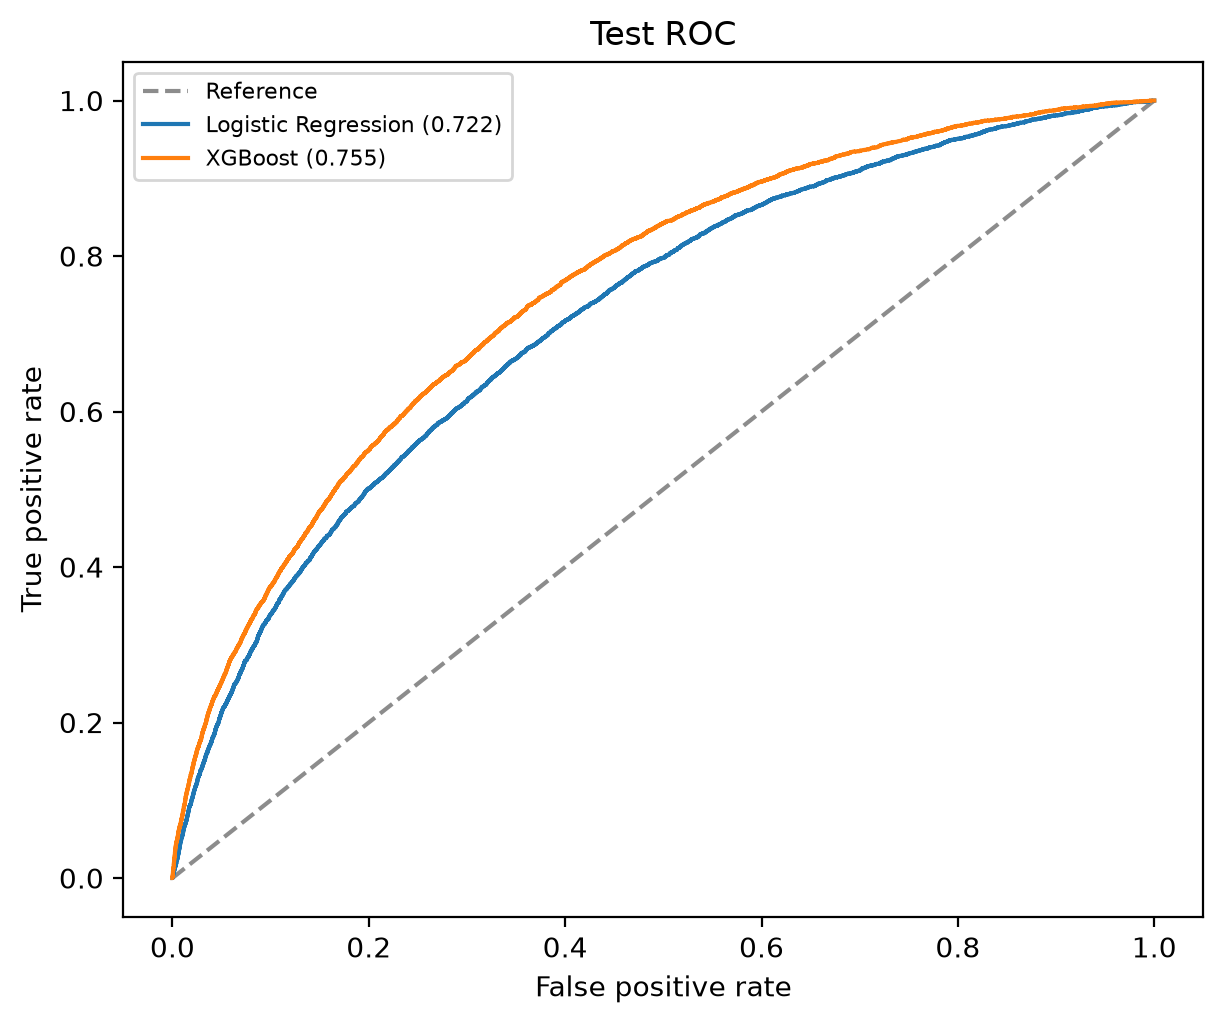

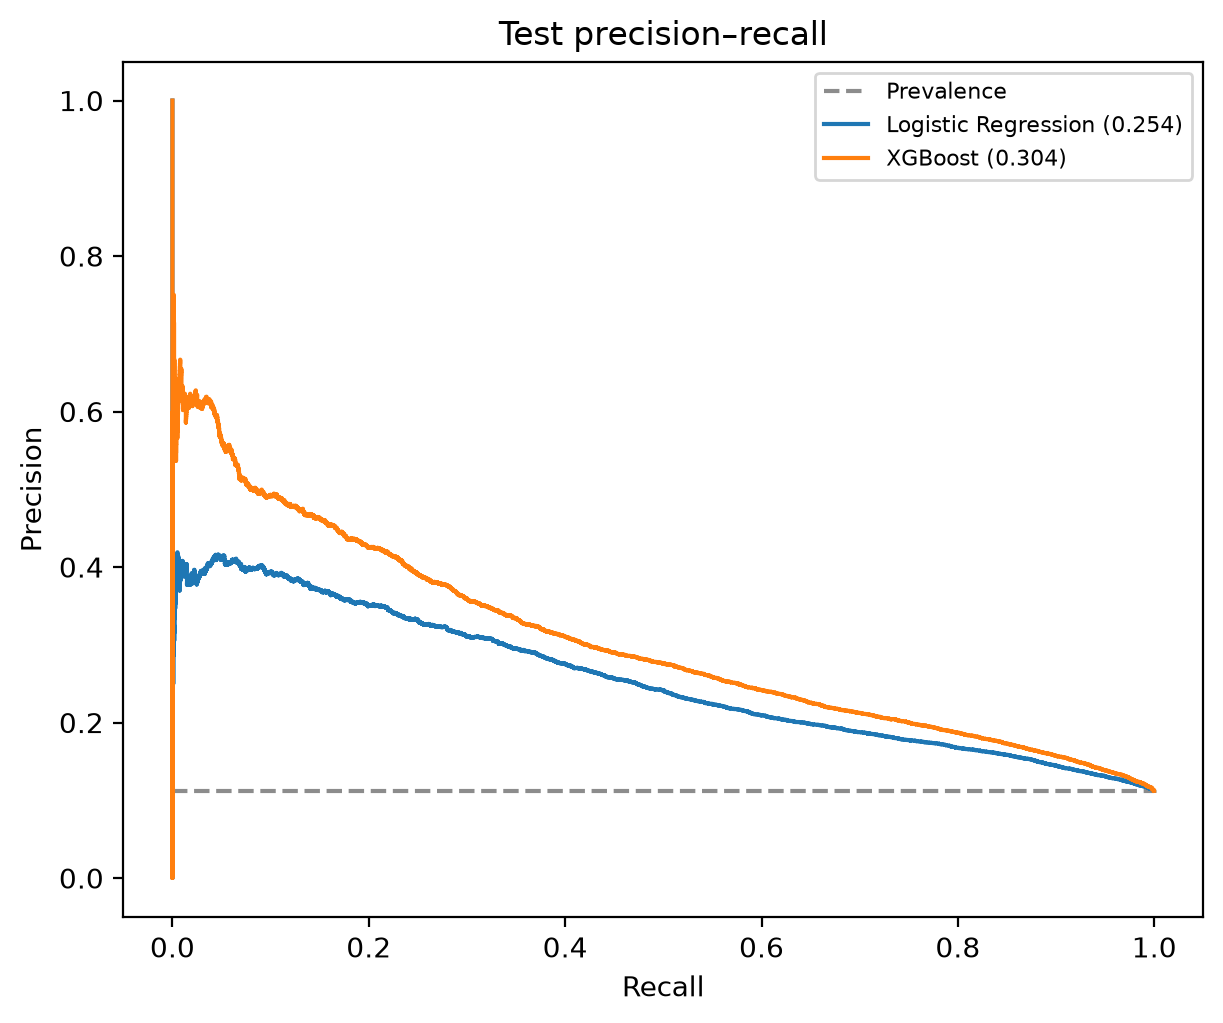

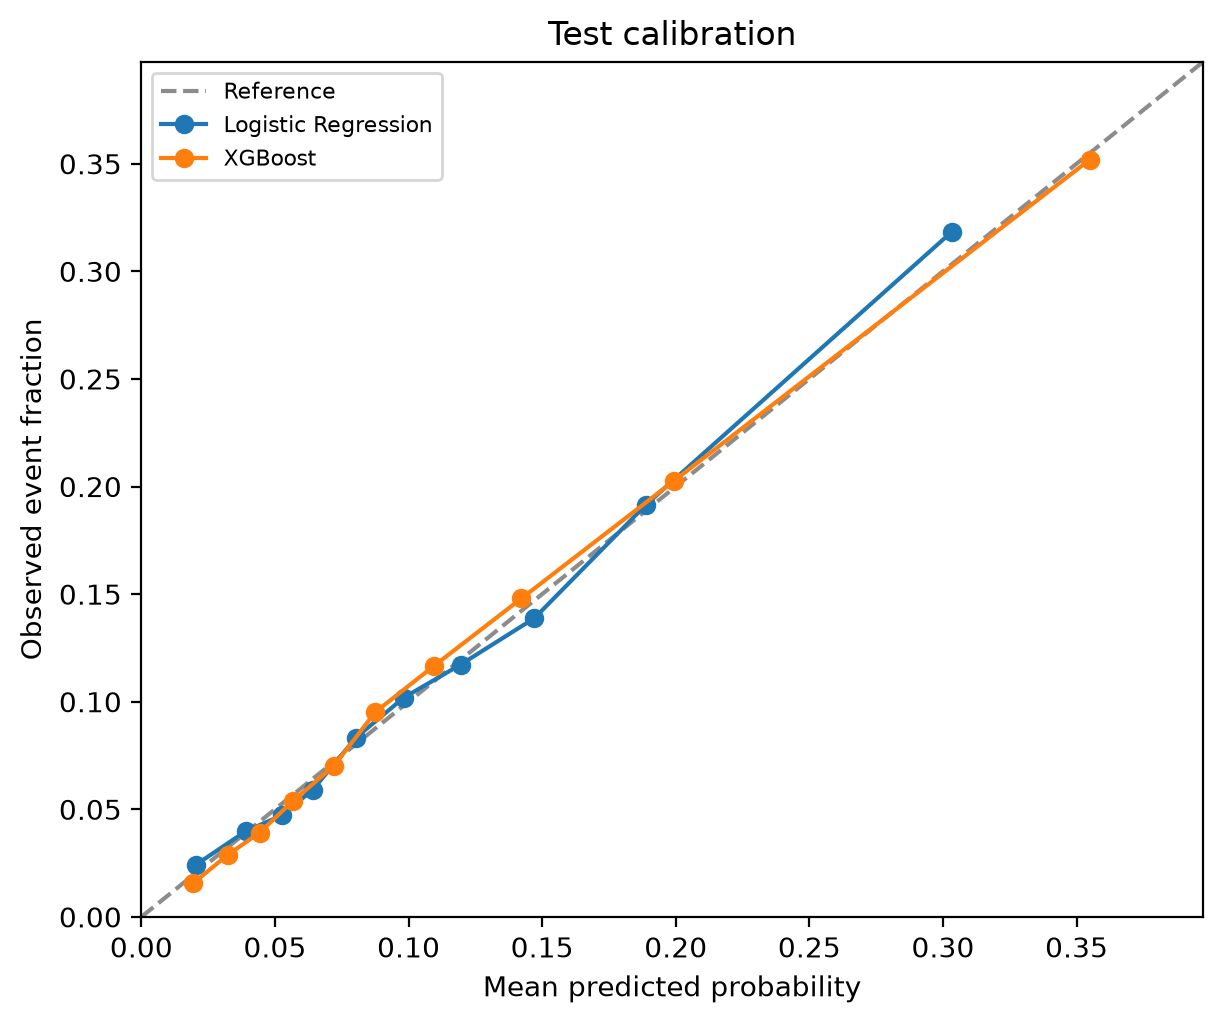

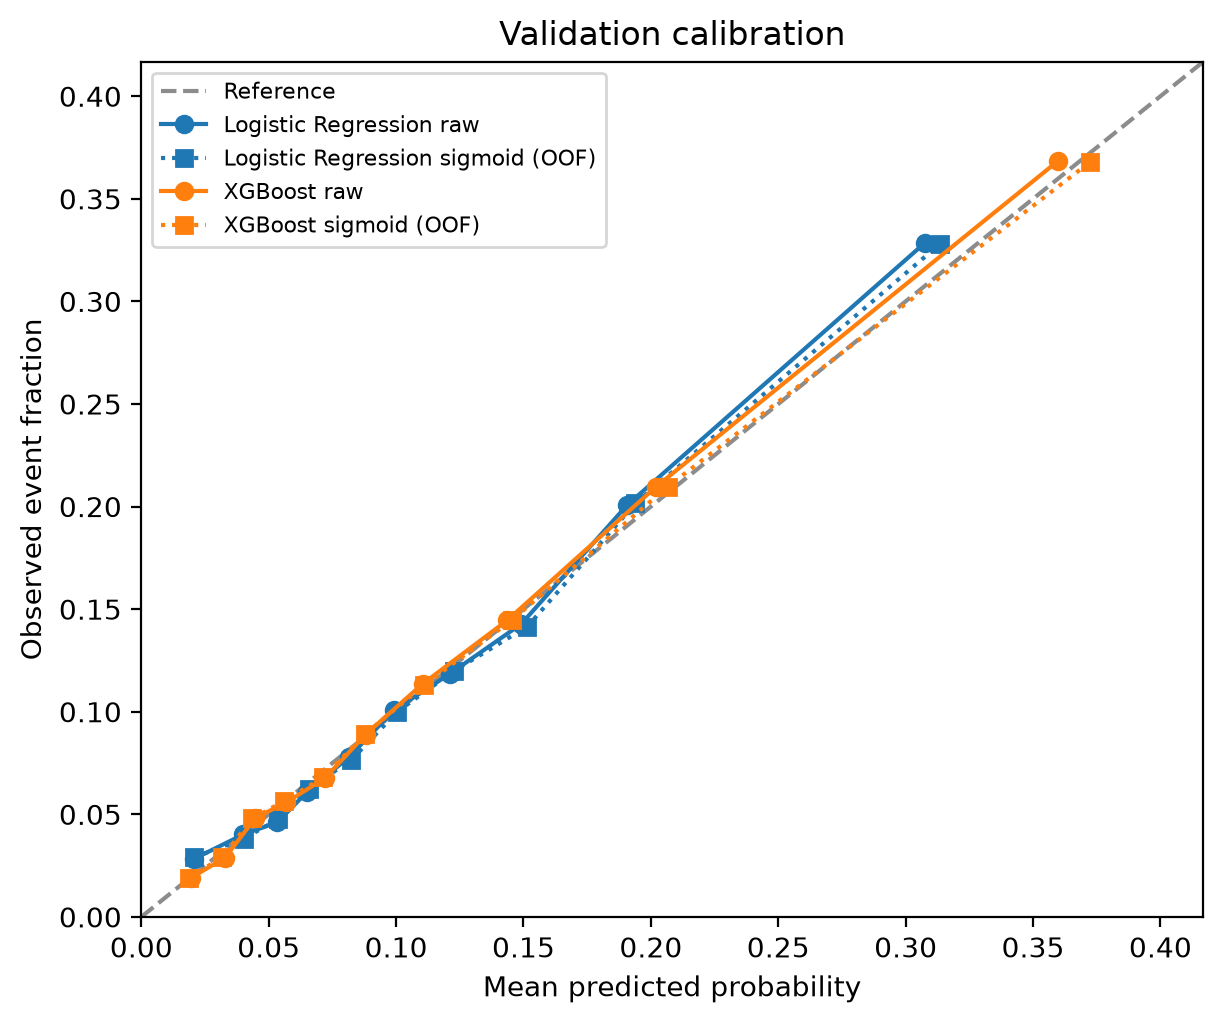

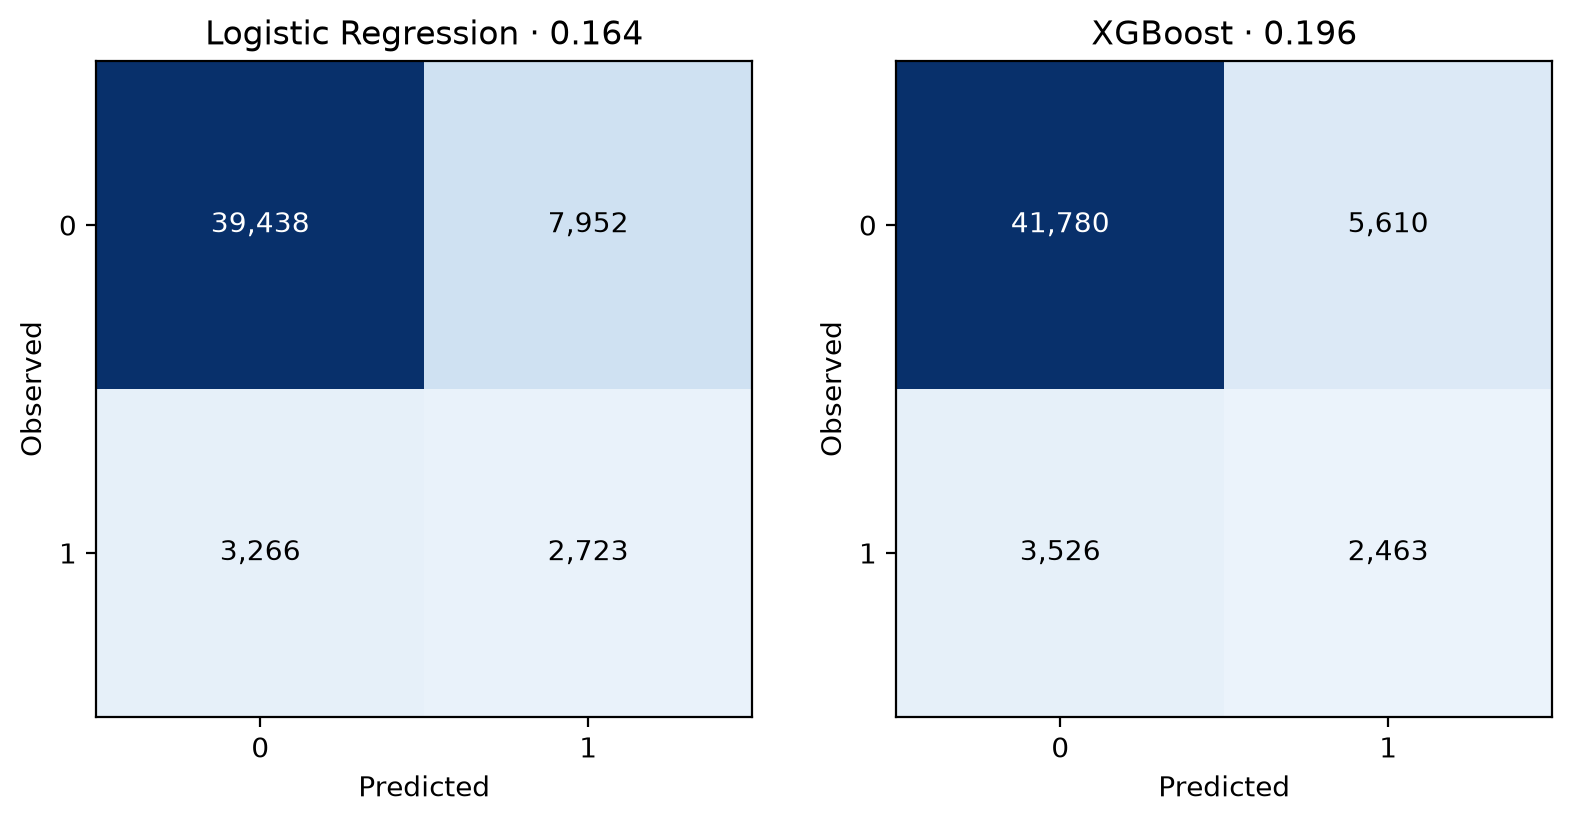

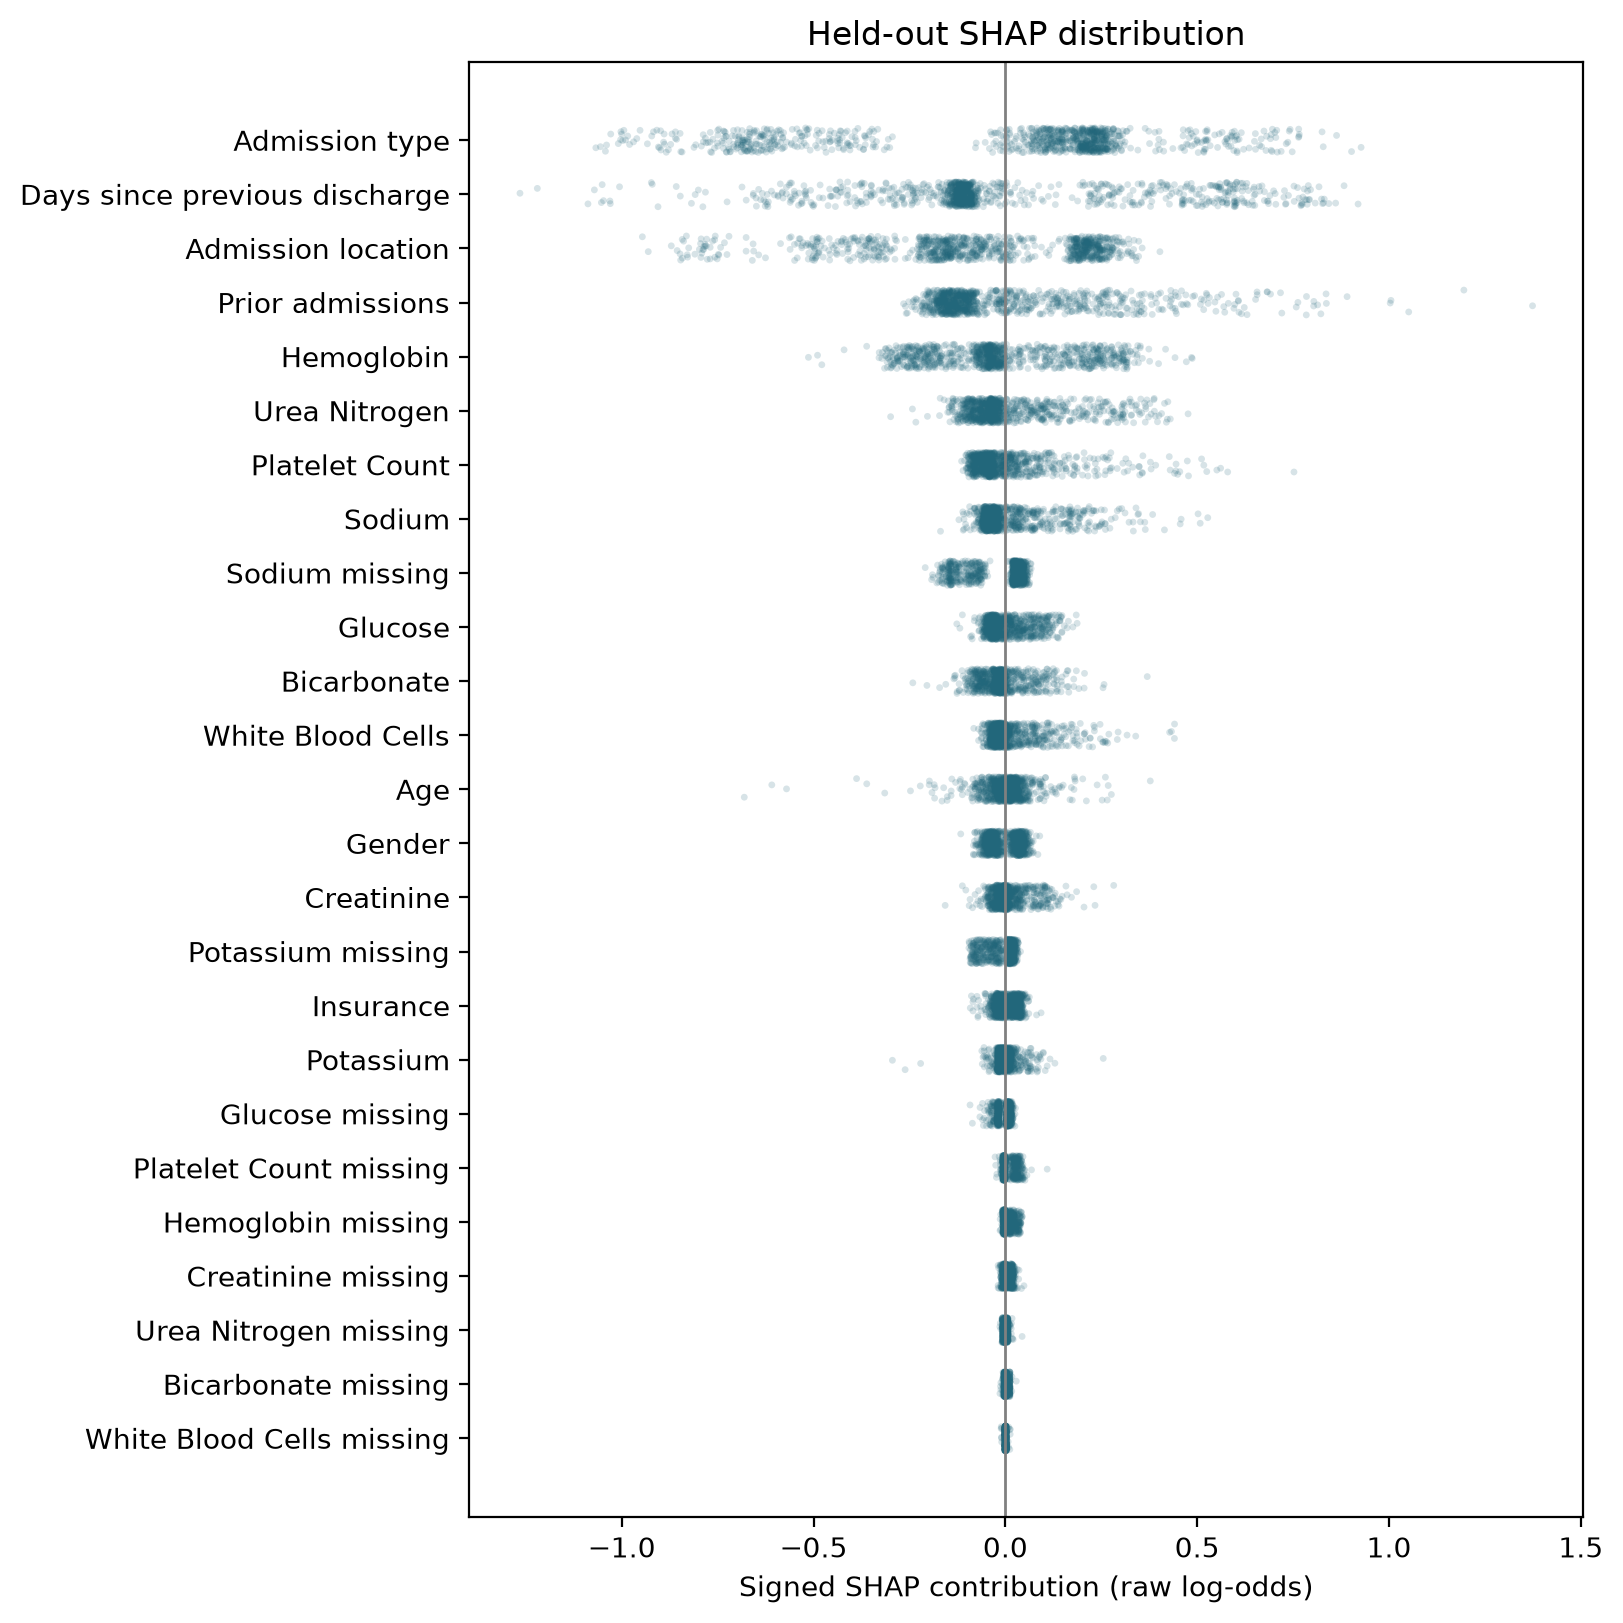

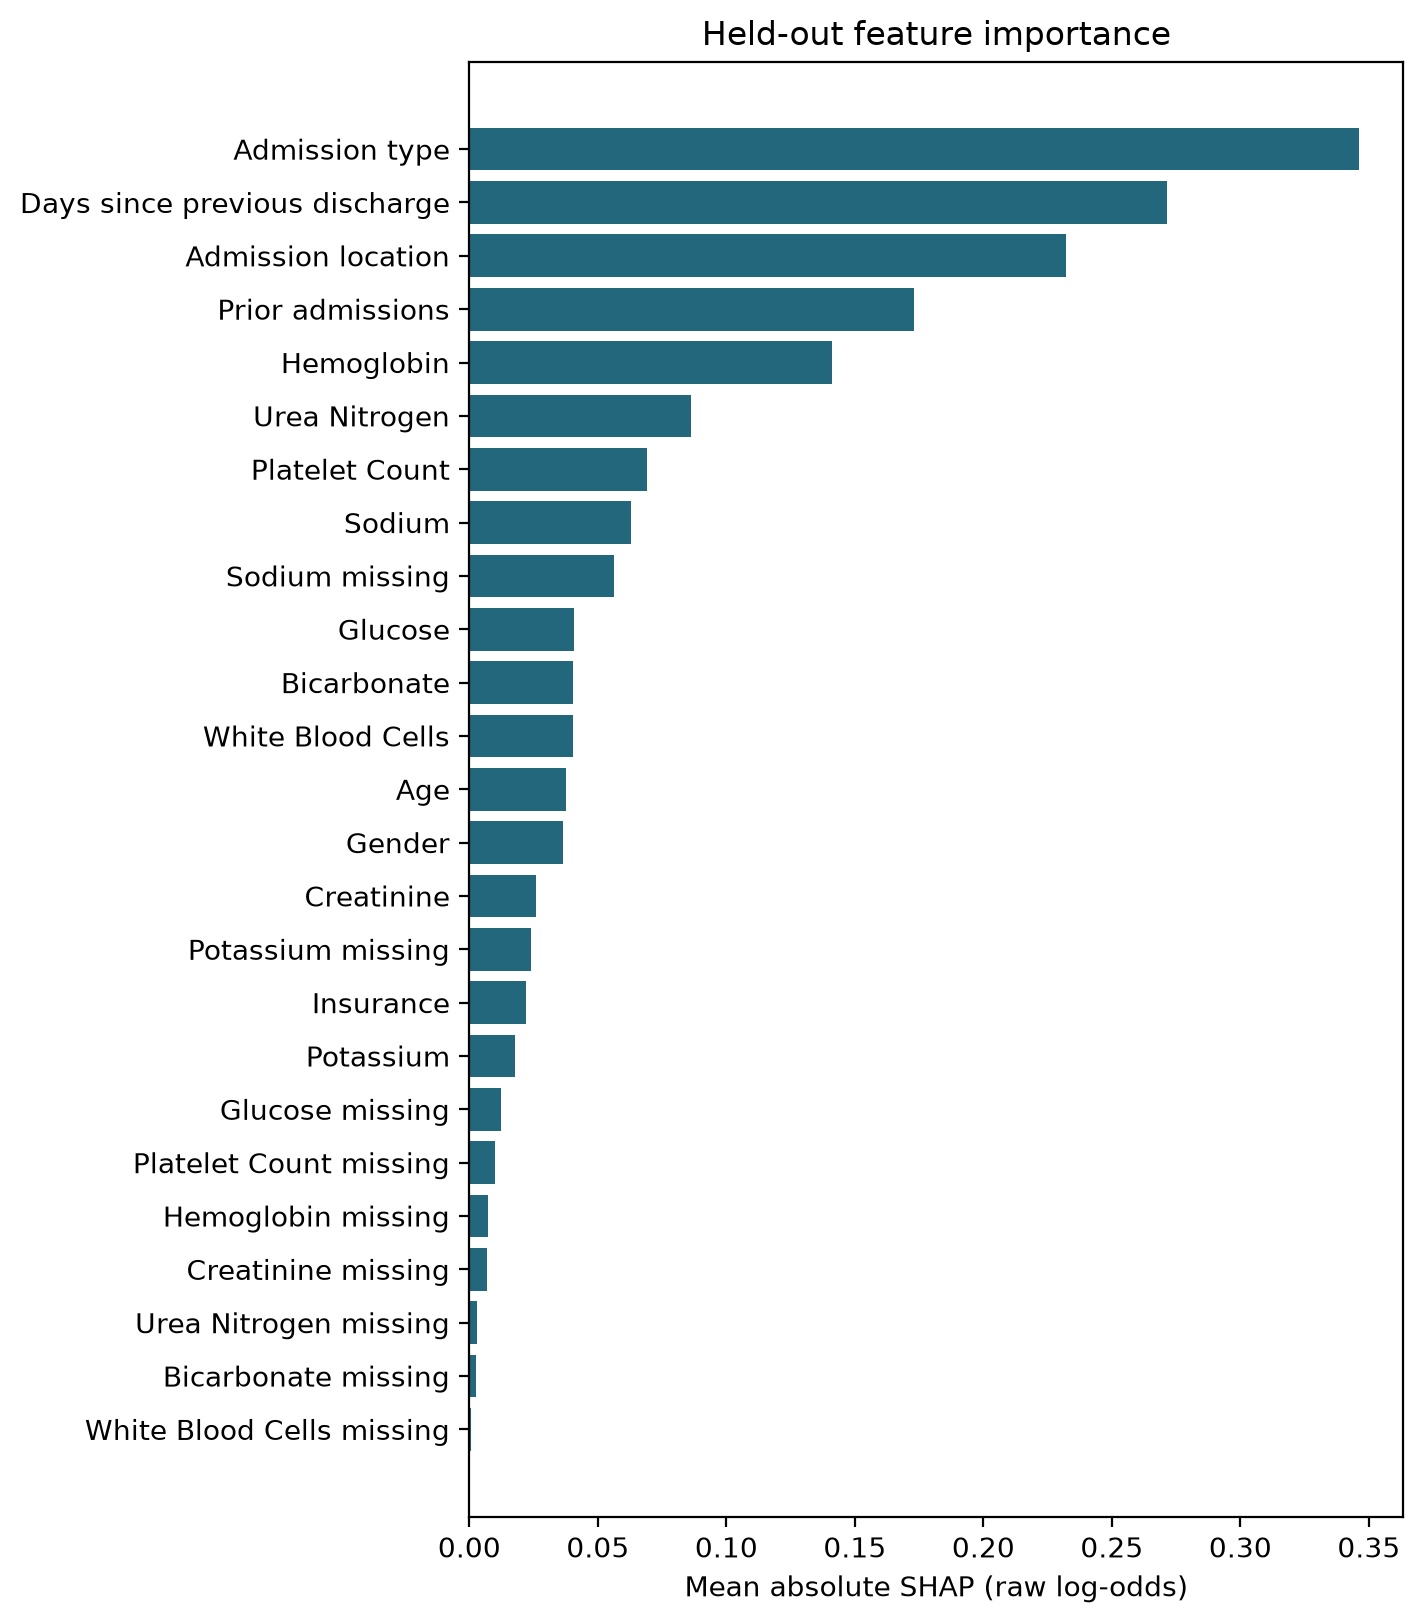

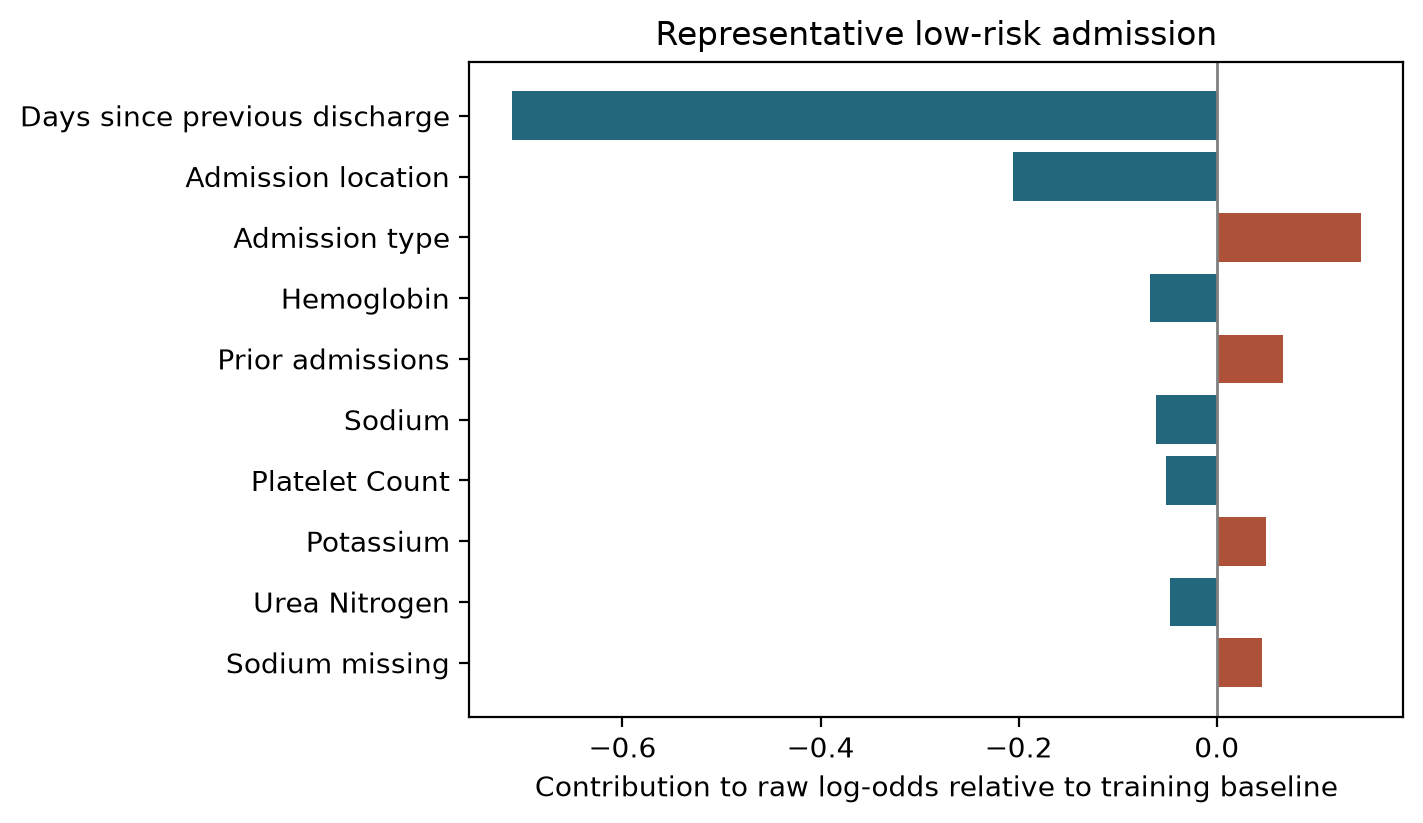

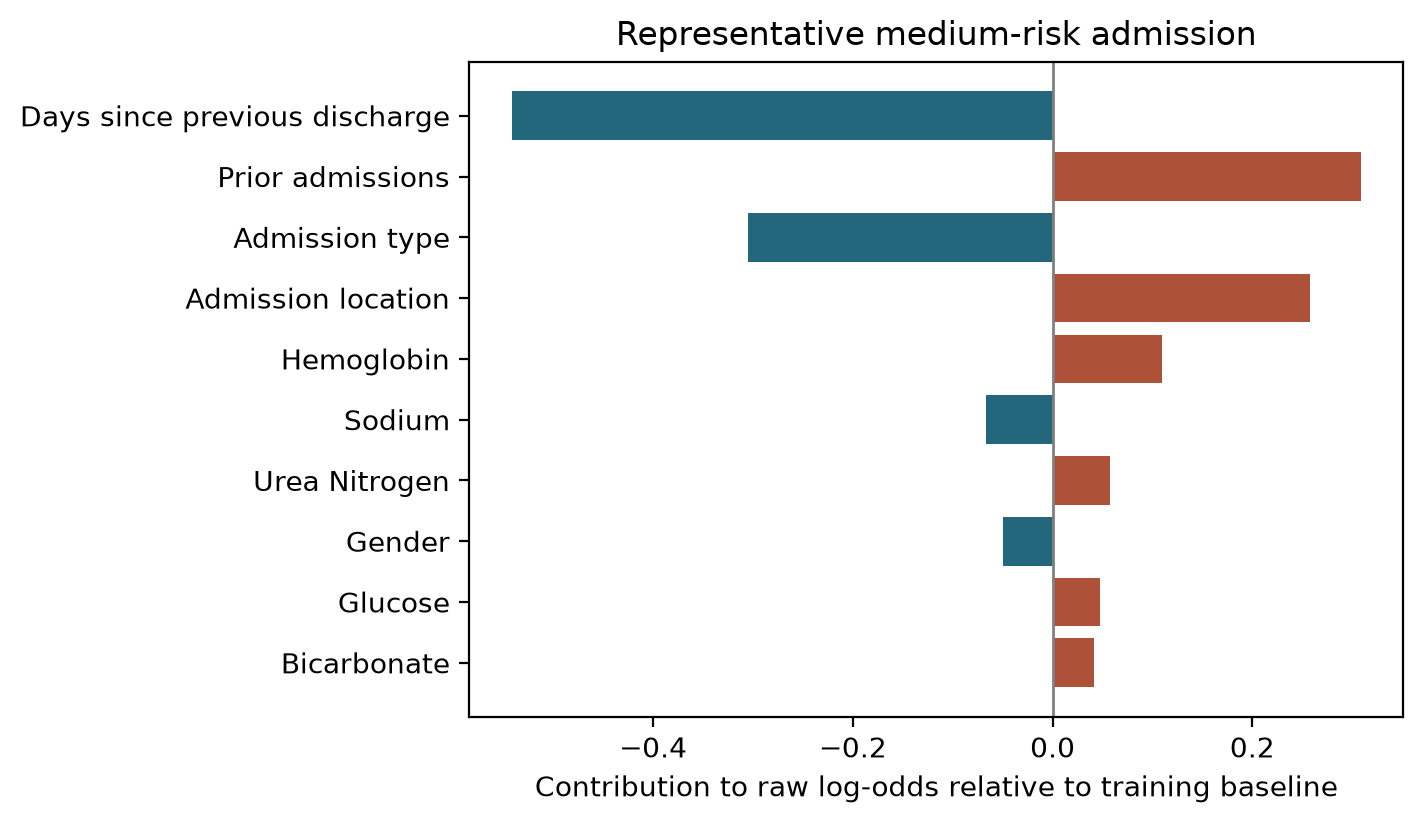

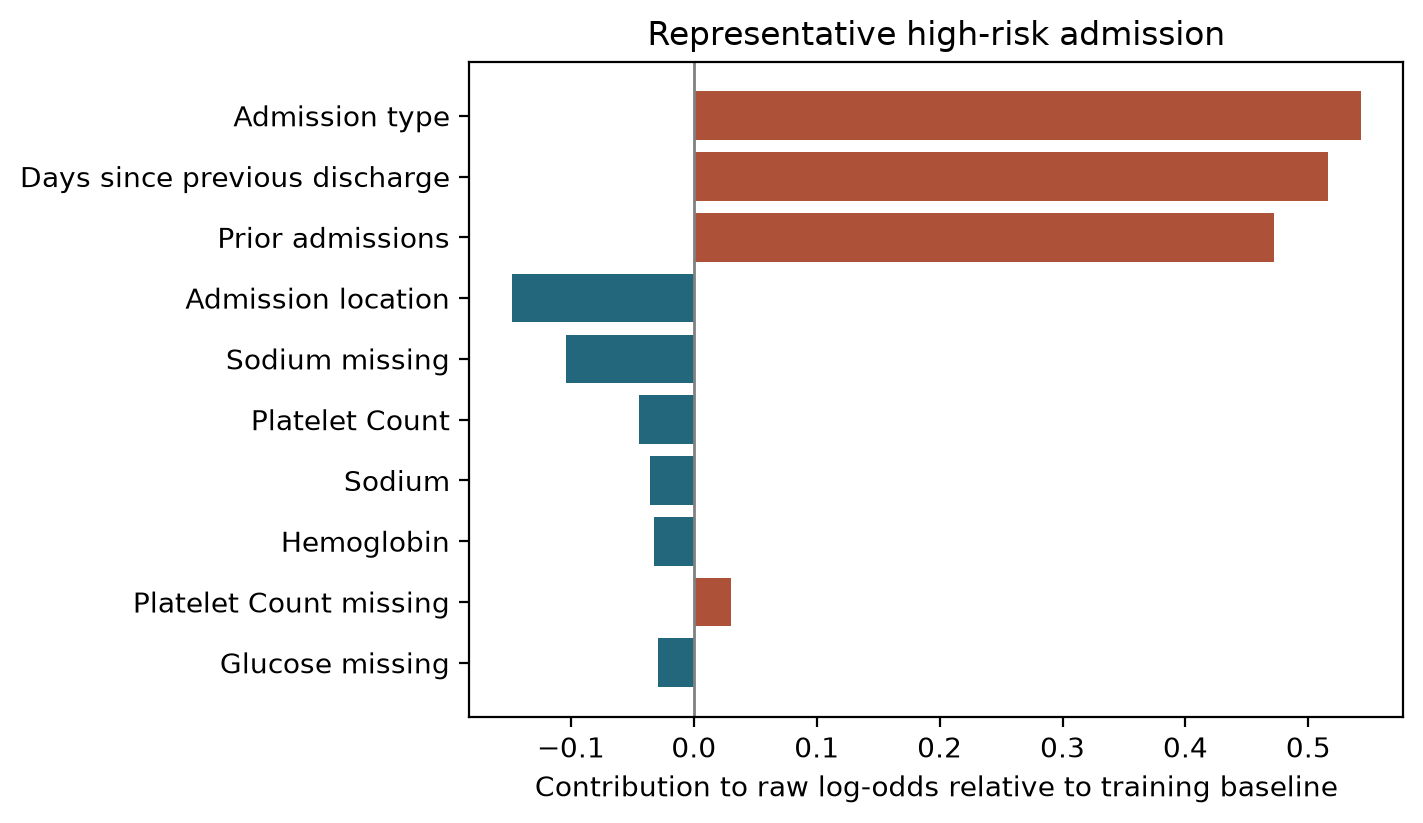

In [13]:
if manifest:
    print(manifest["primary"]["rationale"])
    for figure in ("roc", "precision_recall", "calibration", "validation_calibration",
                   "confusion_matrices", "shap_summary", "shap_importance",
                   "local_low", "local_medium", "local_high"):
        display(Image(filename=str(bundle / f"{figure}.png"), width=640))